# 2025年度最低賃金の発効時期と採用の構成（課題3・4）

第12表の合計・パート・パート以外の新規求人を使い、2025年11月の「早期−後期」差が**求人全体の縮小**か**パートとパート以外の構成の違い**かを調べる。

- 実行方法：このディレクトリで `python build_notebook.py`（または VS Code / Jupyter で必要なライブラリのあるPythonを選び、上から実行）。
- 依存：pandas, numpy, scipy, matplotlib, openpyxl, pymupdf。乱数は使わない。
- 数値はすべて `data/raw/` の政府統計から再計算する。`results/` の既存CSVは読まない。
- 求人≠採用≠雇用。パート以外は正社員だけではない。因果効果の推定ではない。

## 1. データの読み込みと検査

第12表のシートは 1=パート含む一般（合計）、2=パート除く一般、3=一般パート。年・年度別は月平均なので、`月` 列に値がある行だけを使う。

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd
import analysis

frames, audit = analysis.load_vacancies(analysis.RAW/'estat_shokugyo_t12_shinki_kyujin.xlsx')
pd.DataFrame(audit).T

,sheet,title,months,prefectures,start,end,national_max_abs_residual,missing_cells
total,第１２表－１（パート含む一般）,都道府県（受理地）別 雇用形態別 新規求人数（実数）（パートタイムを含む一般）,164,47,2013-01,2026-08,0.0,0
nonpart,第１２表ー２（パート除く一般）,都道府県（受理地）別 雇用形態別 新規求人数（実数）（パートタイムを除く一般）,164,47,2013-01,2026-08,0.0,0
part,第１２表－３（一般パート）,都道府県（受理地）別 雇用形態別 新規求人数（実数）（一般パートタイム）,164,47,2013-01,2026-08,0.0,0
part_plus_nonpart_max_abs_residual,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
# 全国＝47県の和、パート＋パート以外＝合計（いずれも最大残差0）
print('47都道府県:', len(frames['part'].columns)-1)
print('月数:', len(frames['part']))
print('パート＋パート以外＝合計 の最大残差:', audit['part_plus_nonpart_max_abs_residual'])

47都道府県: 47
月数: 164
パート＋パート以外＝合計 の最大残差: 0.0


## 2. 最低賃金と発効時期グループ

年度見出し（令和6年度・令和7年度）で列を選ぶ。11月発効の13県は主比較から外す。

In [3]:
prefs = frames['part'].drop(columns='全国').columns.tolist()
policy, headers = analysis.load_policy(analysis.RAW/'mhlw_saitei_chingin_kaitei.xlsx', prefs)
print(json.dumps(headers, ensure_ascii=False))
policy.groupby('group')[['mw_2024','mw_2025','raise_yen','raise_pct']].agg(['size','mean']).round(2)

{"2024": {"header": "令和６年度", "zero_based_wage_column": 45, "zero_based_date_column": 46, "excel_rows": "3:49"}, "2025": {"header": "令和７年度", "zero_based_wage_column": 47, "zero_based_date_column": 48, "excel_rows": "3:49"}}


mw_2024          mw_2025          raise_yen        raise_pct      
            size     mean    size     mean      size   mean      size  mean
group                                                                      
early         20  1025.45      20  1090.65        20  65.20        20  6.39
excluded      13   995.92      13  1063.54        13  67.62        13  6.82
late          14   961.93      14  1036.71        14  74.79        14  7.78

In [4]:
# 独立の公式PDF（令和7年度 地域別最低賃金額一覧）と47県を照合
analysis.check_policy_pdf(policy)

{'pdf_page': 3,
 'matched_prefectures': 47,
 'source_sha256': 'ce45876d2ad29c59f1f930849a069e7e68ecb512a6770fa9fb0b48680dbd01ea'}

## 3. 指標

- 前年同月比：$y_{i,t}=100(\ln V_{i,t}-\ln V_{i,t-12})$
- 11月の差：$d_i=y_{i,\mathrm{Nov}}-\overline{y_{i,\mathrm{Jan..Sep}}}$、$D=\bar d_{\text{早期}}-\bar d_{\text{後期}}$
- 相対：$d^{P/N}=d^{P}-d^{N}$（県内の型別差。非処理の対照ではない）
- パート比率：$100(s_{i,\mathrm{Nov}}-s_{i,\mathrm{Nov}-12})$

In [5]:
levels, metrics, share = analysis.prepare_metrics(frames)
print('相対＝パート−パート以外 の恒等性を確認済み')
metrics['part'].loc['2025-01':'2025-11'].mean(axis=0).describe().round(2)

相対＝パート−パート以外 の恒等性を確認済み


count    47.00
mean     -5.99
std       3.17
min     -14.08
25%      -8.03
50%      -5.92
75%      -3.80
max       0.81
dtype: float64

## 4. 主結果（基準：2025年1〜9月）

In [6]:
summary, deltas, means = analysis.estimate(metrics, policy, '2025-09')
summary[['metric','estimate','ci_low','ci_high','p_negative','p_two_sided','n_early','n_late']].round(3)

,metric,estimate,ci_low,ci_high,p_negative,p_two_sided,n_early,n_late
0,total,-0.149,-4.150,3.853,0.470,0.939,20,14
1,nonpart,0.672,-3.022,4.366,0.646,0.709,20,14
2,part,-1.555,-7.934,4.823,0.310,0.620,20,14
3,relative,-2.227,-8.045,3.591,0.220,0.440,20,14
4,share_pp,-0.510,-1.846,0.825,0.221,0.441,20,14


In [7]:
means.round(2)

,metric,baseline_end,group,n,baseline,november,change
0,total,2025-09,early,20,-2.90,-10.06,-7.16
1,total,2025-09,late,14,-3.31,-10.32,-7.01
2,nonpart,2025-09,early,20,-2.12,-8.84,-6.72
3,nonpart,2025-09,late,14,-1.92,-9.32,-7.40
4,part,2025-09,early,20,-4.18,-11.99,-7.81
5,part,2025-09,late,14,-5.80,-12.06,-6.25
6,relative,2025-09,early,20,-2.06,-3.15,-1.08
7,relative,2025-09,late,14,-3.88,-2.74,1.14
8,share_pp,2025-09,early,20,-0.48,-0.74,-0.26
9,share_pp,2025-09,late,14,-0.88,-0.63,0.25


## 5. 推移（図）

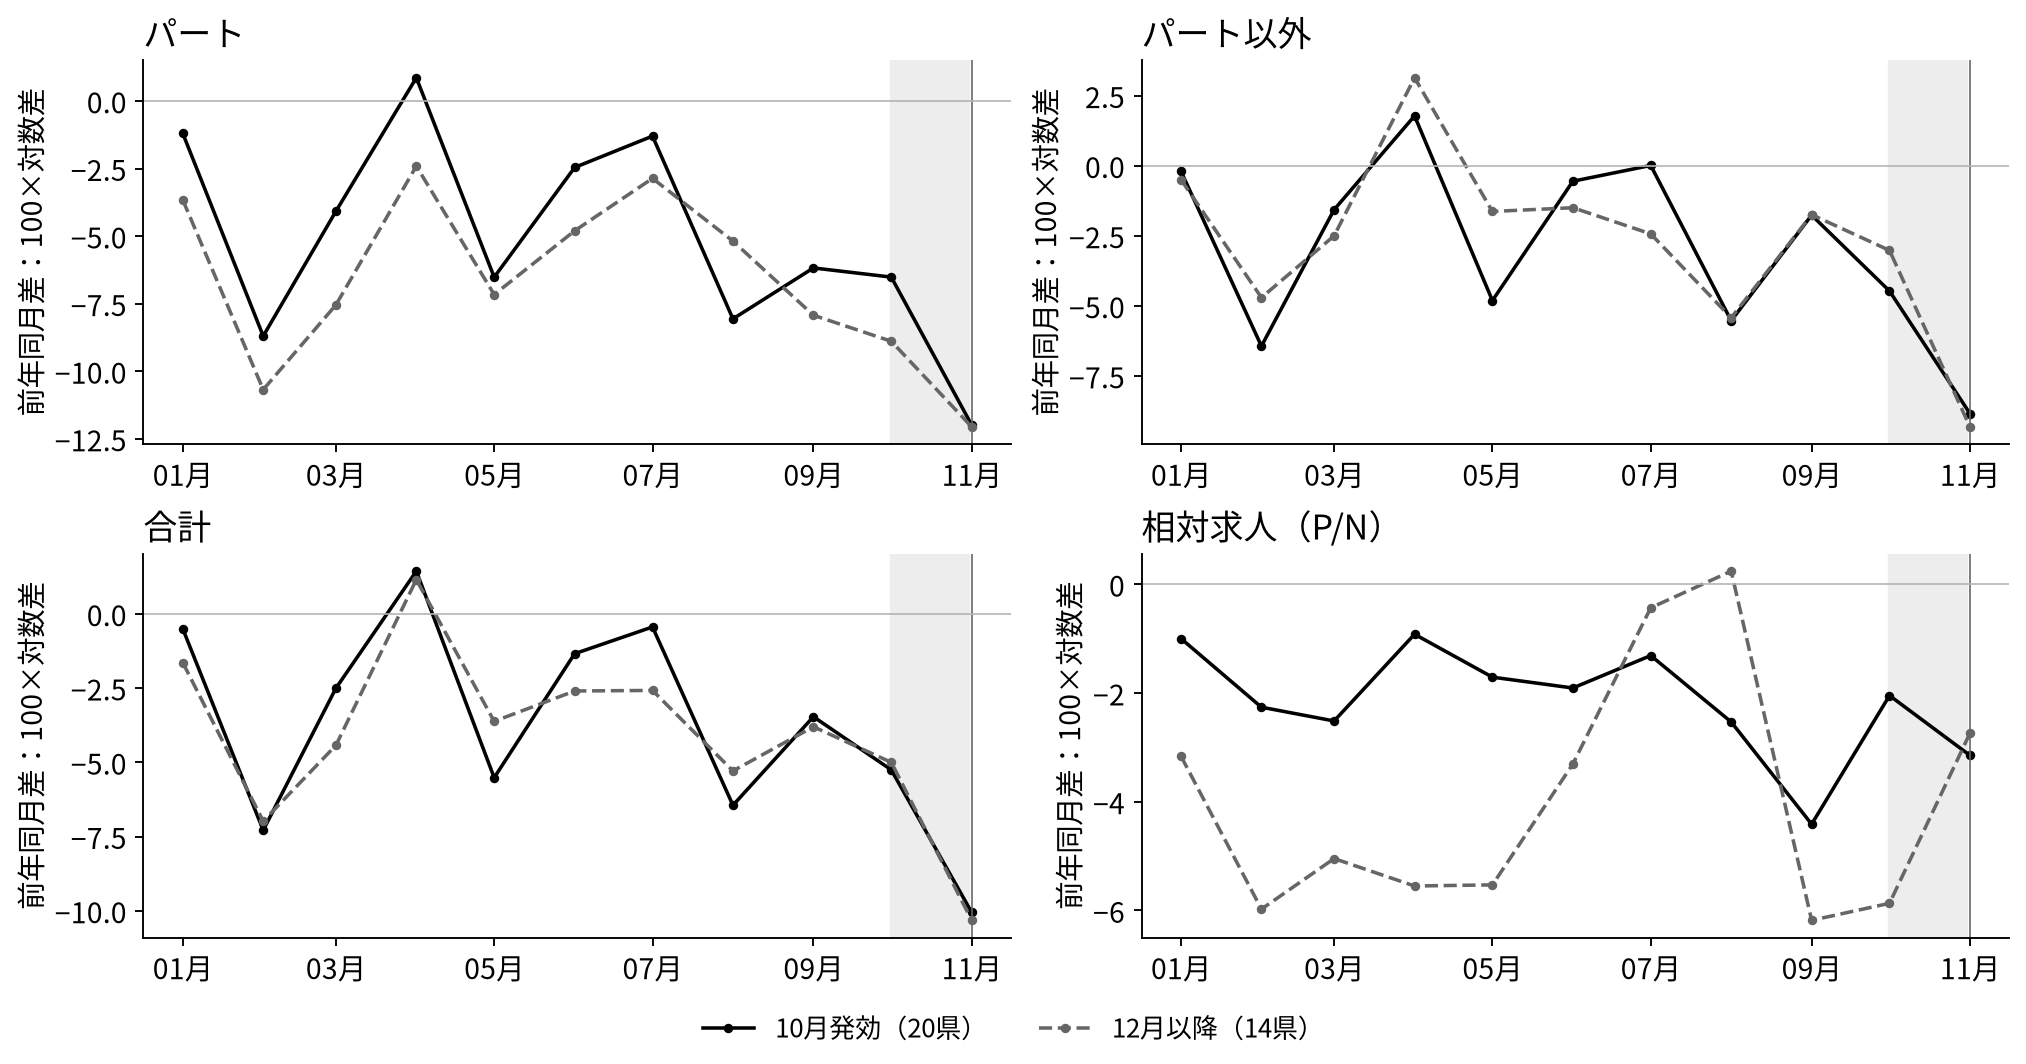

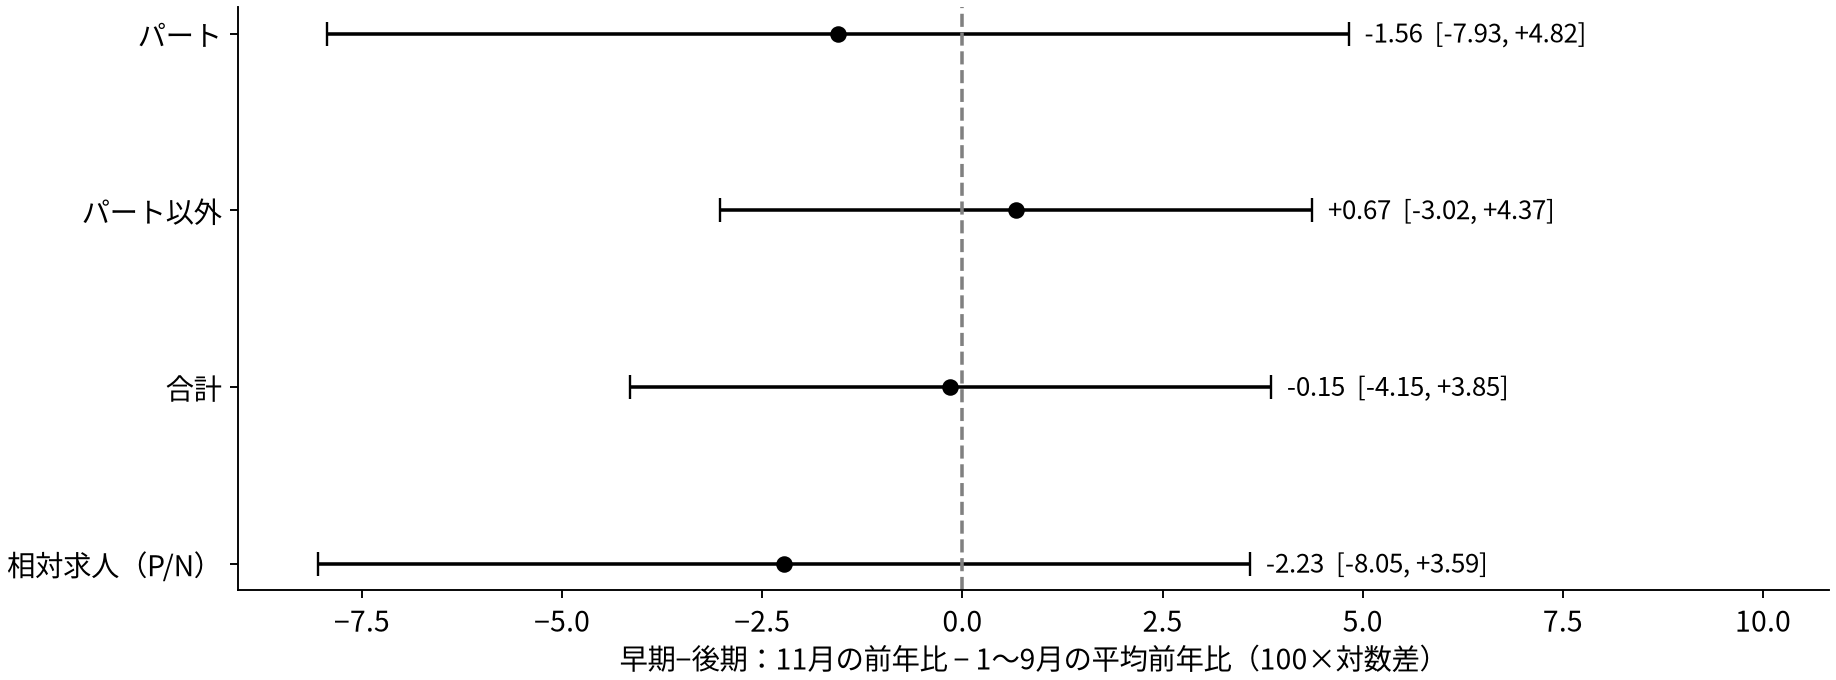

In [8]:
analysis.make_figures(metrics, policy, pd.concat([analysis.estimate(metrics, policy, e)[0] for e in ['2025-09','2025-07']], ignore_index=True))
from IPython.display import Image, display
display(Image(filename='assets/observed_trends.png'))
display(Image(filename='assets/observed_contrasts.png'))

## 6. 基準期間の変更（1〜7月）

In [9]:
alt, _, _ = analysis.estimate(metrics, policy, '2025-07')
alt[['metric','estimate','ci_low','ci_high','p_negative']].round(3)

,metric,estimate,ci_low,ci_high,p_negative
0,total,-0.383,-4.648,3.881,0.426
1,nonpart,0.711,-3.227,4.648,0.645
2,part,-2.180,-8.848,4.488,0.253
3,relative,-2.891,-8.902,3.121,0.167
4,share_pp,-0.671,-2.053,0.711,0.165


## 7. モデルの数値検算（推定ではない）

CES の相対需要と規模効果の式が実装と一致するか、極限（Leontief, Cobb–Douglas）で破綻しないかを確認する。パラメータは仮定値。新規部門の採用を当期労働投入とし、単価 c は1人の期間賃金と採用経費の合計。既存従業員・補充採用を省く追加仮定を置く。

In [10]:
checks = analysis.model_checks()
checks

{'probes': 63,
 'max_relative_ratio_error': 9.992007221626409e-16,
 'max_primal_error': 2.8656410577809766e-11,
 'max_dual_error': 6.661338147750939e-16,
 'max_derivative_error': np.float64(2.809180492224783e-06),
 'max_common_scale_error': 1.5557888310979706e-11,
 'leontief_limit': True,
 'cobb_douglas_limit': True,
 'parameters_estimated': False}

In [11]:
# パート費用だけ10%上げたときの符号（σ, β で変わる）
rows=[]
for sigma in [1.2, 2.0, 8.0]:
    for beta in [0.2, 0.5, 0.9]:
        b=analysis.ces_choice(1,1,sigma=sigma,beta=beta); x=analysis.ces_choice(1.1,1,sigma=sigma,beta=beta)
        rows.append(dict(sigma=sigma,beta=beta,
                         part=100*np.log(x['P']/b['P']), nonpart=100*np.log(x['N']/b['N']),
                         relative=100*np.log((x['P']/x['N'])/(b['P']/b['N']))))
pd.DataFrame(rows).round(2)

,sigma,beta,part,nonpart,relative
0,1.2,0.2,-11.67,-0.24,-11.44
1,1.2,0.5,-15.23,-3.79,-11.44
2,1.2,0.9,-53.17,-41.74,-11.44
3,2.0,0.2,-15.57,3.49,-19.06
4,2.0,0.5,-19.06,-0.00,-19.06
5,2.0,0.9,-56.28,-37.22,-19.06
6,8.0,0.2,-49.35,26.90,-76.25
7,8.0,0.5,-52.34,23.91,-76.25
8,8.0,0.9,-84.22,-7.97,-76.25


## 8. まとめ

- 合計の差はほぼ0、相対は負（-2.23）だが区間は0を含む。**構成の方向は仮説と整合するが、統計的には言えない**。
- モデルはパート以外の符号を一意に決めない。したがって nonpart を「対照群」と呼ぶことも、企業内代替の因果的な証拠とすることもできない。
- 限界：発効時期は外生でない、同比は前年の政策効果も引く、受理地統計、求人≠採用≠雇用、20県対14県で検出力が低い。